# Лабораторная работа № 2. Задание № 1.
> Григорьев Никита M3338, Паховский Иван M3339

### Условие варианта № 3
Методом максимального правдоподобия найти оценку параметра $\theta$ биномиального распределения $\text{Bin}(m, \theta)$, считая $m$ известным. Эксперимент при $m = 4$, $\theta = 1/5$.

### Поиск оценки с помощью метода максимального правдоподобия

Пусть мы сгенерировали $n$ независимых случайных величин $X_i$, для которых $P(X_i = k_i) = C_m^{k_i}\cdot\theta^{k_i}\cdot(1-\theta)^{m-k+i}$,

тогда $P(X_1=k_1, X_2=k_2,\ldots, X_n=k_n) = P(X_1=k_1)\cdot P(X_2=k_2)\cdot\ldots\cdot P(X_n=k_n)$.

Найдём argmax по $\theta$ от функции совместной вероятности. Для этого найдём производную по $\theta$:
$(P(X_1=k_1, X_2=k_2,\ldots, X_n=k_n))' = C_m^{k_1}\cdot\ldots\cdot C_m^{k_n} \cdot (\theta^{n\overline{X}}\cdot(1-\theta)^{nm-n\overline{X}})' = $ \
 $ = C_m^{k_1}\cdot\ldots\cdot C_m^{k_n} \cdot \theta^{n\overline{X}-1}\cdot (1 - \theta)^{nm-n\overline{X}-1}\cdot(n\overline{X}\cdot (1-\theta) - \theta\cdot (nm-n\overline{X}))$

Точки, в которых производная равна нулю:
- $\theta_0=0$
- $\theta_1=\frac{\overline{X}}{m}$
- $\theta_2=1$

Максимум функции достигается в $\theta_0=0$ когда все $k_i = 0$, в $\theta_2=1$ когда все $k_i=m$, в остальных случаях точкой максимума является $\theta_1=\frac{\overline{X}}{m}$.

### Свойства полученной оценки

#### 1) Смещение
$\operatorname{Bias} \hat{\theta} = \mathbb E\hat{\theta} - \theta = \frac{1}{mn}\mathbb E(X_1+\ldots + X_n) - \theta = \frac{1}{m}EX-\theta = [\mathbb EX = m\cdot\theta] = \frac{m\cdot\theta}{m}-\theta = 0$

#### 2) Дисперсия

$\mathbb Var\hat\theta = \mathbb Var(\frac{\sum X_i}{nm}) = \frac{1}{n^2 m^2}\mathbb Var(\sum X_i) = \frac{1}{n m^2}\mathbb Var(X_i) = \frac{\theta(1-\theta)}{nm}$


#### 3) Среднеквадратичная ошибка
$\operatorname{MSE}\hat\theta = \mathbb E(\hat\theta-\theta)^2 = (\operatorname{Bias} \hat{\theta})^2 + \mathbb Var\hat\theta = \mathbb Var\hat\theta =  \frac{\theta(1-\theta)}{m}$

---
#### 1) Оценка несмещённая

#### 2) Состоятельность:
По теореме, если модель регулярна и уравнение правдоподобия имеет единственное решение $\hat\theta$, то $\hat\theta \xrightarrow{p} \theta$

Покажем, что модель регулярна:
1. Параметрическое множество $\Theta=(0,1)$ открыто. Для $\theta_1\ne\theta_2$ $P_{\theta_1}(X=k)\ne P_{\theta_2}(X=k)$
2. Носитель распределения $\{0,1,\ldots,m\}$ не зависит от $\theta$.
3. Сумма по $k=0,\ldots,m$ конечна, поэтому дифференцирование можно переставлять с суммированием.

#### 3) Асимптотическая нормальность:
$\sqrt{n}(\hat\theta - \theta) \xrightarrow{d} \mathcal N(0,\sigma^2)$

По ЦПТ: $\sqrt{n}(\overline{X} - \mathbb EX) \xrightarrow{d} \mathcal N(0,\sigma^2)$
Тогда:
 $$\mathbb EX = m\theta$$
$$\sqrt{n}(\frac{\overline{X}}{m} - \theta) \xrightarrow{d} \mathcal N(0,\sigma^2)$$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

M = 4
THETA = 1 / 5

SAMPLE_SIZES = [10, 100, 1000, 10000]
NUM_SAMPLES = 10000

In [2]:
samples = []

for n in SAMPLE_SIZES:
    samples.append([])
    for _ in range(NUM_SAMPLES):
        samples[-1].append(np.random.binomial(n = M, p = THETA, size = n))

In [3]:
theta_estimations = []

for samples_i in samples:
    theta_estimations.append([])

    for sample in samples_i:
        theta_estimations[-1].append(np.mean(sample) / M)


In [4]:
data_summary = {
    "Размер выборки (n)": SAMPLE_SIZES,
    "Выборочное среднее оценки (E)": [np.mean(est) for est in theta_estimations],
    "Выборочная дисперсия оценки (Var)": [np.var(est, ddof=1) for est in theta_estimations]
}

df_results = pd.DataFrame(data_summary)

pd.options.display.float_format = '{:.6f}'.format

df_results


,Размер выборки (n),Выборочное среднее оценки (E),Выборочная дисперсия оценки (Var)
0,10,0.199520,0.004058
1,100,0.199847,0.000400
2,1000,0.199911,0.000040
3,10000,0.199968,0.000004


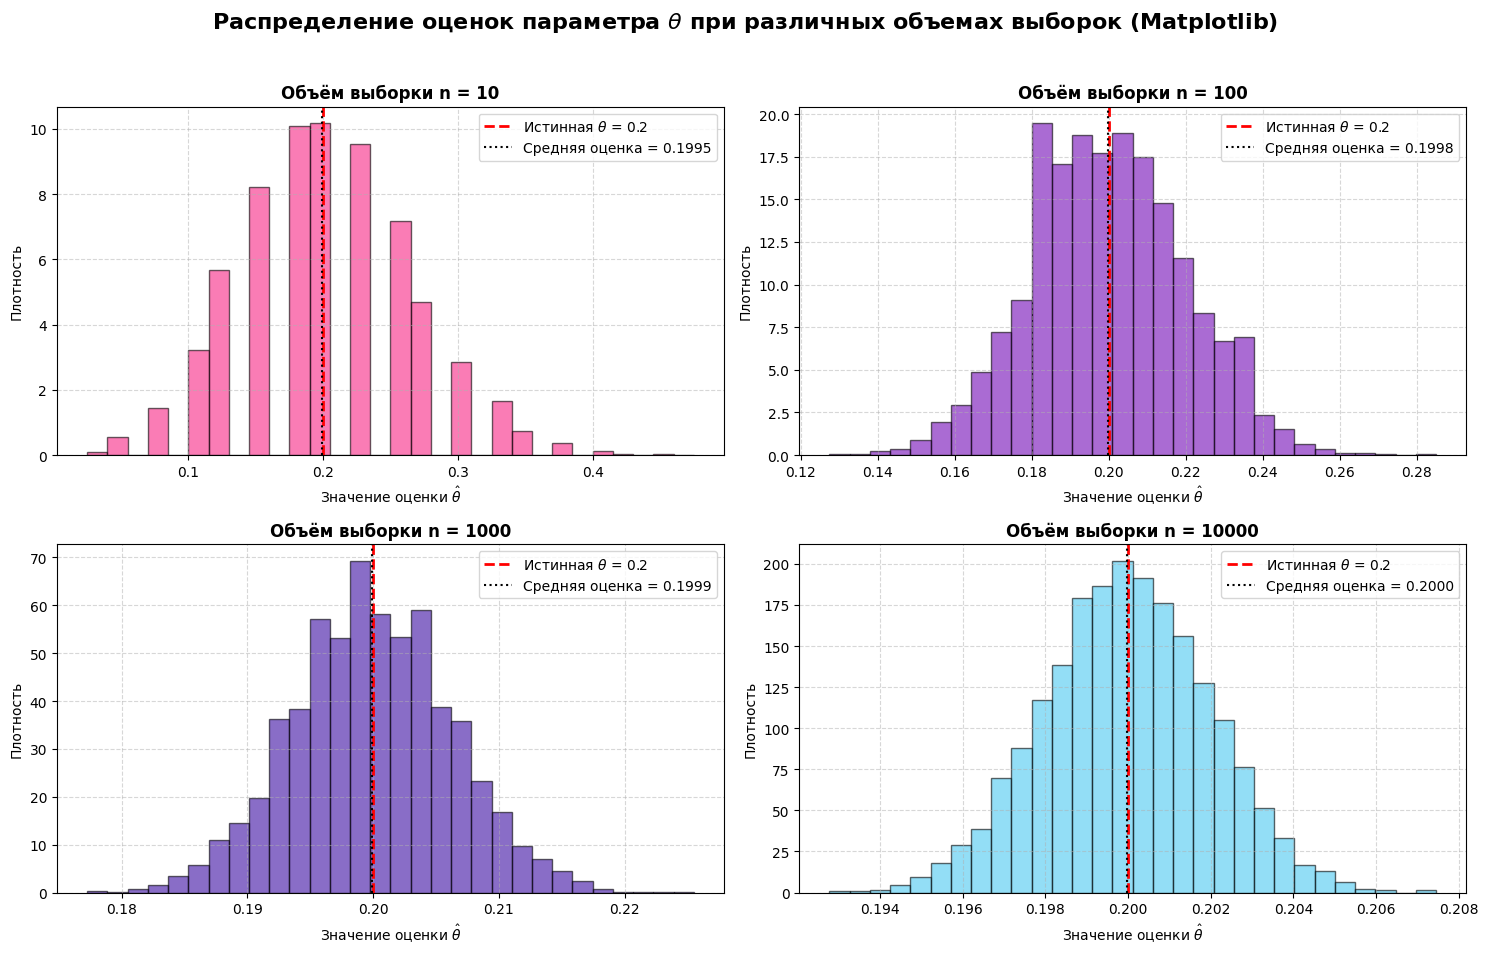

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

colors = ["#f72585", "#7209b7", "#3a0ca3", "#4cc9f0"]

for i, n in enumerate(SAMPLE_SIZES):
    axes[i].hist(
        theta_estimations[i],
        bins=30,
        density=True,
        color=colors[i],
        edgecolor="black",
        alpha=0.6
    )

    axes[i].axvline(THETA, color="red", linestyle="--", linewidth=2, label=f"Истинная $\\theta$ = {THETA}")

    mean_est = np.mean(theta_estimations[i])
    axes[i].axvline(mean_est, color="black", linestyle=":", linewidth=1.5, label=f"Средняя оценка = {mean_est:.4f}")

    axes[i].set_title(f"Объём выборки n = {n}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Значение оценки $\\hat{\\theta}$")
    axes[i].set_ylabel("Плотность")
    axes[i].grid(True, linestyle="--", alpha=0.5)
    axes[i].legend(loc="upper right", fontsize=10)

plt.suptitle("Распределение оценок параметра $\\theta$ при различных объемах выборок (Matplotlib)", fontsize=16, fontweight='bold', y=0.95)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
